# Q0 · 00 · Literature Note and Data Audit (Phase Q0-P0)

**Purpose.** Before anything is frozen, check two things:

1. **What has already been done** (literature note), so Q0 adds something new rather than repeating it.
2. **What data exist** for each of the 11 sectors × 11 countries: how far back, how often, and whether each series is
   long enough for the tests in the design (§5). This sets a go / no-go per sector.

Nothing here looks at *when* booms happened. Only coverage (start, end, number of observations) is measured, so the
audit cannot bias the definitions frozen in P1.

**Licensed data.** Passport and Orbis files are read for coverage metadata only (years and counts). No licensed
values are printed.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parents[1]))
from series.config import COUNTRIES, NAME, SECTORS, RAW, MANUAL, PROC, LICENSED
from series import fetch
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 20, "display.max_colwidth", 60)
FIG = Path("../reports/figures"); FIG.mkdir(parents=True, exist_ok=True)

## 1 · Literature note: what exists, and where Q0 fits

| Strand | Key work | What it does | What it does not do |
|---|---|---|---|
| **Industry sizing** | e-Conomy SEA 2016–2025 (Google, Temasek, Bain); 10th edition in 2025 | GMV and revenue by sector; SEA-6 by country, the other four ASEAN states as one aggregate from 2025; digital financial services as regional totals 2023–2025 | No dated takeoffs; modelled estimates, revised each year; methods unpublished |
| **Policy reviews** | ERIA (ASEAN Digital Integration; ASEAN Digital Community 2025) | Policy frameworks (digital masterplans, the ASEAN Digital Economy Framework Agreement (DEFA)), ICT-sector structure | Not about which consumer sectors boomed |
| **Takeoff measurement** | Golder & Tellis (1997); Tellis, Stremersch & Yin (2003); Stremersch & Tellis (2004) | Threshold rule for takeoff; slowdown rule; international comparisons | Physical consumer durables, mostly Europe, pre-2000 |
| **Cross-country spillover** | Van Everdingen, Fok & Stremersch (2009), *JMR* | Takeoffs abroad speed up a country's own takeoff; stronger between close economies (8 products, 55 countries) | Not digital services; not SEA |
| **Adoption lags** | Comin & Hobijn (2010); Comin & Mestieri (2018), *AEJ: Macro* | Poorer countries now adopt new technologies early but use them far less intensively | Broad technologies (internet, phones), not sectors |
| **Adoption determinants** | ASEAN e-commerce panels; cross-country mobile-money studies (Findex) | Correlates of adoption levels | No dating of booms; mostly cross-sections or surveys |

**Gap Q0 fills.** No source found dates *when and where* each SEA digital-economy sector took off with a validated
rule, separates booms from spikes, or checks timing across independent sources.

**Two design implications.**
* Comin & Mestieri's split between *arrival* and *intensity* suggests reporting both the takeoff year and the
  post-takeoff level (depth) in the catalogue.
* Van Everdingen et al. (2009) is the established model for Q1 (cross-country takeoff spillovers), so Q0's catalogue
  must date takeoffs in a form that model can use (country × sector × year).

**GICS tags verified.** Under the 2023 GICS revision, payment processors (Visa, Mastercard, PayPal) moved from IT to
Financials; ride-hailing (Uber, Lyft) sits in Industrials. All 11 sectors therefore fall outside GICS IT, as the
design states.

## 2 · Candidate sources
Every source considered, with what was found when it was checked (October 2026). "IN HAND" = already downloaded.

In [2]:
reg = pd.read_csv(MANUAL / "source_registry.csv")
reg[["sector", "source", "countries", "frequency", "start", "end", "access", "p0_status"]]

,sector,source,countries,frequency,start,end,access,p0_status
0,ecommerce,Euromonitor Passport,all with Passport coverage,annual,to confirm,2025,UCL licence,EXPORT NEEDED
1,ecommerce,e-Conomy SEA,SEA-6,annual,2019,2025,public PDF,IN HAND
2,ecommerce,World Bank Findex,SEA-9,survey waves,2021,2024,public API,IN HAND
3,ride_hailing,Euromonitor Passport,to confirm,annual,to confirm,2025,UCL licence,EXPORT NEEDED
4,ride_hailing,e-Conomy SEA,SEA-6,annual,2019,2025,public PDF,IN HAND
5,food_delivery,Euromonitor Passport,SEA-6,annual,2020,2025,UCL licence,IN HAND
6,online_travel,Euromonitor Passport,to confirm,annual,to confirm,2025,UCL licence,EXPORT NEEDED
7,online_travel,e-Conomy SEA,SEA-6,annual,2019,2025,public PDF,IN HAND
8,online_media,Euromonitor Passport,to confirm,annual,to confirm,2025,UCL licence,EXPORT NEEDED
9,online_media,e-Conomy SEA,SEA-6,annual,2019,2025,public PDF,IN HAND


## 3 · Coverage of the data in hand
Each candidate series is reduced to one row: sector, country, source, frequency, first year with a non-zero value,
last year, and the number of annual (or monthly) observations from that first non-zero year.

In [3]:
rows = []
def add(sector, iso3, source, freq, s, metric):
    """s: pandas Series indexed by period (int year, or Timestamp for monthly), non-zero values only."""
    s = s.dropna()
    s = s[s > 0]
    if s.empty:
        return
    if freq == "monthly":
        rows.append(dict(sector=sector, iso3=iso3, source=source, metric=metric, freq=freq,
                         first=s.index.min().year, last=s.index.max().year, n_annual=s.index.year.nunique(),
                         n_monthly=len(s)))
    else:
        rows.append(dict(sector=sector, iso3=iso3, source=source, metric=metric, freq=freq,
                         first=int(s.index.min()), last=int(s.index.max()), n_annual=len(s), n_monthly=0))

# --- IMF FAS: digital payments (mobile money) and digital banking (mobile/internet banking)
fas = fetch.fetch_imf_fas()
# two measures per sector: transaction value (% GDP) and transaction count (per 1,000 adults), which some countries
# report without the value
for ind, sector in [("mobile_money_tx_value_pct_gdp", "digital_payments"),
                    ("mobile_money_tx_per_1000_adults", "digital_payments"),
                    ("mobile_internet_banking_tx_value_pct_gdp", "digital_banking"),
                    ("mobile_internet_banking_tx_per_1000_adults", "digital_banking")]:
    for iso3, g in fas[fas.indicator == ind].groupby("iso3"):
        add(sector, iso3, "IMF FAS", "annual", g.set_index("year").value.sort_index(), ind)

# --- e-Conomy SEA (Project 2 transcription): latest edition's value for each year
ec = pd.read_csv(MANUAL / "econsea_levels.csv").sort_values("edition").drop_duplicates(["iso3", "sector", "year"], keep="last")
ec_map = {"ecommerce": ["ecommerce"], "transport_food": ["ride_hailing", "food_delivery"],
          "online_travel": ["online_travel"], "online_media": ["online_media"]}
for (iso3, sec), g in ec.groupby(["iso3", "sector"]):
    for sector in ec_map[sec]:
        add(sector, iso3, "e-Conomy SEA" + (" (transport+food combined)" if sec == "transport_food" else ""),
            "annual", g.set_index("year").gmv_usd_b.sort_index(), "gmv_usd_b")

# --- Euromonitor Passport (licensed): coverage only
pp = pd.read_excel(sorted((LICENSED / "passport").glob("*.xls"))[0], header=None, engine="xlrd")
hdr = pp.iloc[5].tolist()
ycols = [i for i, v in enumerate(hdr) if isinstance(v, (int, float)) and not pd.isna(v) and 1990 < v < 2100]
for _, r in pp.iloc[6:].iterrows():
    iso3 = {v[0]: k for k, v in COUNTRIES.items()}.get(r[0])
    if iso3:
        s = pd.Series([pd.to_numeric(r[i], errors="coerce") for i in ycols], index=[int(hdr[i]) for i in ycols])
        add("food_delivery", iso3, "Euromonitor Passport", "annual", s, "online_ordering_value")

# --- Bank Indonesia SSKI Table 12: P2P lending (annual 2018–2020, monthly from Jan 2021)
bi = pd.read_excel(RAW / "central_banks" / "IDN" / "bi_sski_tabel_12_p2p_lending.xls", header=None, engine="calamine")
years = bi.iloc[4].ffill(); months = bi.iloc[5]
loans = bi.iloc[31]                                                       # accumulated loans, total (Rp bn)
mon = {}
for j in range(3, bi.shape[1]):
    if isinstance(months[j], str) and isinstance(years[j], (int, float)) and not pd.isna(years[j]):
        mon[pd.Timestamp(f"{int(years[j])}-{months[j]}-01")] = pd.to_numeric(loans[j], errors="coerce")
add("digital_lending", "IDN", "Bank Indonesia SSKI T12", "monthly", pd.Series(mon).sort_index(), "accumulated_p2p_loans")

# --- Crypto: Chainalysis ranks (Project 2) and Orbis new crypto firms (licensed, coverage only)
ch = pd.read_csv(MANUAL / "chainalysis_ranks.csv")
for iso3, g in ch.groupby("iso3"):
    add("crypto", iso3, "Chainalysis index (rank)", "annual", g.groupby("edition").overall_rank.min(), "rank")
orb = pd.read_parquet(LICENSED / "orbis_firm_formation_PRELIMINARY.parquet")
for iso3, g in orb[orb.kind == "crypto"].groupby("iso3"):
    # firm formation counts can be zero in early years; coverage = years from first firm to 2025
    s = g.set_index("year").new_firms.sort_index()
    first = s[s > 0].index.min()
    add("crypto", iso3, "Orbis new crypto firms", "annual", s.loc[first:].replace(0, 1e-9), "new_firms")

# --- Findex (survey waves): level cross-checks for several sectors
fx = fetch.fetch_findex()
fx_map = {"bought_online_with_phone_or_internet_pct": "ecommerce", "made_digital_payment_pct": "digital_payments",
          "received_loan_mobile_pct": "digital_lending", "received_domestic_remittances_into_account_pct": "remittances",
          "received_intl_remittances_pct": "remittances", "paid_insurance_regularly_pct": "invest_insure"}
for (ind, iso3), g in fx[fx.indicator.isin(fx_map)].groupby(["indicator", "iso3"]):
    add(fx_map[ind], iso3, "World Bank Findex (survey)", "survey", g.set_index("year").value.sort_index(), ind)

cov = pd.DataFrame(rows)
print(f"{len(cov)} candidate series in hand")
cov.sort_values(["sector", "iso3", "source"]).reset_index(drop=True)

128 candidate series in hand


,sector,iso3,source,metric,freq,first,last,n_annual,n_monthly
0,crypto,IDN,Chainalysis index (rank),rank,annual,2022,2026,5,0
1,crypto,IDN,Orbis new crypto firms,new_firms,annual,2007,2025,19,0
2,crypto,KHM,Chainalysis index (rank),rank,annual,2024,2025,2,0
3,crypto,MYS,Orbis new crypto firms,new_firms,annual,2005,2025,21,0
4,crypto,PHL,Chainalysis index (rank),rank,annual,2022,2026,5,0
...,...,...,...,...,...,...,...,...,...
123,ride_hailing,MYS,e-Conomy SEA (transport+food combined),gmv_usd_b,annual,2019,2025,7,0
124,ride_hailing,PHL,e-Conomy SEA (transport+food combined),gmv_usd_b,annual,2019,2025,7,0
125,ride_hailing,SGP,e-Conomy SEA (transport+food combined),gmv_usd_b,annual,2019,2025,7,0
126,ride_hailing,THA,e-Conomy SEA (transport+food combined),gmv_usd_b,annual,2019,2025,7,0


## 4 · Minimum-data rule (proposed; frozen in P1)

The same thresholds apply to every sector, so no sector passes on weaker evidence.

| Test | Minimum | Why |
|---|---|---|
| **Takeoff dating** (annual totals) | ≥ 8 annual observations from the first non-zero year | The rule needs a base period plus enough years after takeoff to confirm a boom (≥ 3 growth years) |
| **Structural break** (Bai–Perron) | ≥ 15 annual or ≥ 48 monthly observations | With a 15% trimming and up to 2 breaks, each segment needs enough points for a growth rate |
| **Bubble test** (Phillips–Shi–Yu GSADF) | ≥ 60 monthly observations | The recursive test needs a long sample; annual SEA series (≤ 22 points) are too short |
| **Source agreement** | ≥ 2 sources with ≥ 5 overlapping years | To compare dated takeoffs |

**Correction to the design text.** The draft said "≥ 8 annual or ≥ 36 monthly observations for takeoff dating".
Takeoff is dated on annual totals, and 36 months give only three annual totals, so monthly data cannot rescue
takeoff dating. Monthly series are used for the break and bubble tests instead. This is proposed for P1.

In [4]:
cov["takeoff_ok"] = (cov.freq != "survey") & (cov.n_annual >= 8)
cov["break_ok"] = ((cov.freq == "annual") & (cov.n_annual >= 15)) | ((cov.freq == "monthly") & (cov.n_monthly >= 48))
cov["bubble_ok"] = (cov.freq == "monthly") & (cov.n_monthly >= 60)
cov[cov.freq != "survey"].sort_values(["sector", "iso3"])[
    ["sector", "iso3", "source", "freq", "first", "last", "n_annual", "n_monthly", "takeoff_ok", "break_ok", "bubble_ok"]
].reset_index(drop=True)

,sector,iso3,source,freq,first,last,n_annual,n_monthly,takeoff_ok,break_ok,bubble_ok
0,crypto,IDN,Chainalysis index (rank),annual,2022,2026,5,0,False,False,False
1,crypto,IDN,Orbis new crypto firms,annual,2007,2025,19,0,True,True,False
2,crypto,KHM,Chainalysis index (rank),annual,2024,2025,2,0,False,False,False
3,crypto,MYS,Orbis new crypto firms,annual,2005,2025,21,0,True,True,False
4,crypto,PHL,Chainalysis index (rank),annual,2022,2026,5,0,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...
75,ride_hailing,MYS,e-Conomy SEA (transport+food combined),annual,2019,2025,7,0,False,False,False
76,ride_hailing,PHL,e-Conomy SEA (transport+food combined),annual,2019,2025,7,0,False,False,False
77,ride_hailing,SGP,e-Conomy SEA (transport+food combined),annual,2019,2025,7,0,False,False,False
78,ride_hailing,THA,e-Conomy SEA (transport+food combined),annual,2019,2025,7,0,False,False,False


## 5 · Coverage map: best series per sector × country
Cell value = the most annual observations available for that sector × country from any non-survey source.
Green cells (≥ 8) can be dated now; the rest depend on the Passport exports and manual collections in §7.

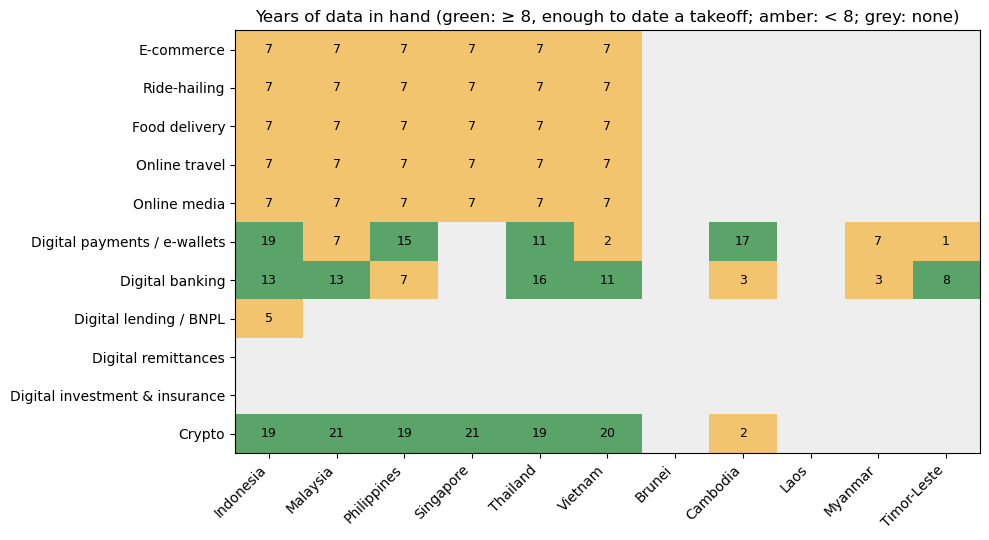

In [5]:
best = (cov[cov.freq != "survey"].groupby(["sector", "iso3"]).n_annual.max()
        .unstack().reindex(index=list(SECTORS), columns=list(COUNTRIES)))
fig, ax = plt.subplots(figsize=(10, 5.5))
show = best.fillna(0).values
im = ax.imshow(np.where(show >= 8, 2, np.where(show > 0, 1, 0)), cmap=plt.matplotlib.colors.ListedColormap(
    ["#eeeeee", "#f2c46d", "#5aa469"]), aspect="auto", vmin=0, vmax=2)
for i in range(show.shape[0]):
    for j in range(show.shape[1]):
        if show[i, j] > 0:
            ax.text(j, i, int(show[i, j]), ha="center", va="center", fontsize=9)
ax.set_xticks(range(len(COUNTRIES)), [NAME[c] for c in COUNTRIES], rotation=45, ha="right")
ax.set_yticks(range(len(SECTORS)), [SECTORS[s]["label"] for s in SECTORS])
ax.set_title("Years of data in hand (green: ≥ 8, enough to date a takeoff; amber: < 8; grey: none)")
plt.tight_layout(); plt.savefig(FIG / "p0_coverage_map.png", dpi=150); plt.show()

## 6 · Verdict per sector (with the data in hand today)

In [6]:
def verdict(g):
    n_take = g[g.takeoff_ok].iso3.nunique()
    n_brk = g[g.break_ok].iso3.nunique()
    n_bub = g[g.bubble_ok].iso3.nunique()
    v = "GO" if n_take >= 5 else "NARROW" if n_take >= 1 or n_brk >= 1 else "NOT TESTABLE YET"
    return pd.Series(dict(countries_any_data=g[g.freq != "survey"].iso3.nunique(), takeoff_testable=n_take,
                          break_testable=n_brk, bubble_testable=n_bub, verdict=v))
ver = cov.groupby("sector").apply(verdict).reindex(list(SECTORS)).fillna(
    dict(countries_any_data=0, takeoff_testable=0, break_testable=0, bubble_testable=0, verdict="NOT TESTABLE YET"))
ver.insert(0, "label", [SECTORS[s]["label"] for s in ver.index])
ver.to_csv(PROC / "q0_p0_verdict.csv")
ver

,label,countries_any_data,takeoff_testable,break_testable,bubble_testable,verdict
sector,,,,,,
ecommerce,E-commerce,6,0,0,0,NOT TESTABLE YET
ride_hailing,Ride-hailing,6,0,0,0,NOT TESTABLE YET
food_delivery,Food delivery,6,0,0,0,NOT TESTABLE YET
online_travel,Online travel,6,0,0,0,NOT TESTABLE YET
online_media,Online media,6,0,0,0,NOT TESTABLE YET
digital_payments,Digital payments / e-wallets,8,4,3,0,NARROW
digital_banking,Digital banking,8,5,1,0,GO
digital_lending,Digital lending / BNPL,1,0,1,1,NARROW
remittances,Digital remittances,0,0,0,0,NOT TESTABLE YET


## 7 · What would move each sector up, and who does it

| Action | Sectors helped | Who |
|---|---|---|
| **Passport exports with the full historic range** (Retail e-commerce; online travel sales; digital media / gaming / video; ride-hailing or mobility if Passport has it; online foodservice ordering re-exported from its earliest year). Select **all 11 SEA countries** and **every available year**, local currency, current prices. | E-commerce, ride-hailing, food delivery, travel, media | You (UCL login) |
| **OJK monthly fintech-lending statistics 2018–2020** (outstanding loans), to extend Bank Indonesia's monthly series back three years | Digital lending (Indonesia) | Me (manual download, one file per month) |
| **Thailand SEC digital-asset monthly reports**: confirm start year, then collect | Crypto (Thailand) | Me |
| **KSEI monthly investor statistics** (connection refused to scripts; may need a browser) | Investment (Indonesia) | Me, with a browser automation tool if needed |
| **World Bank Remittance Prices Worldwide**: digital-channel cost series | Remittances (prices only) | Me |

**Expected outcome after these actions.**
* E-commerce, food delivery, travel and media: GO if Passport goes back to about 2010 or earlier.
* Digital lending: NARROW (Indonesia only, monthly).
* Crypto: NARROW (Thailand monthly, plus Orbis formation with its bias).
* Investment and insurance: likely NARROW (Indonesia investor counts only).
* Remittances: likely NOT TESTABLE as adoption. No SEA country publishes digital-remittance volumes. Prices can be
  reported, but a price fall is not a boom.